In [1]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Part 8: Maximum Likelihood Estimation {-}

\lhead{Part 8: Maximum Likelihood Estimation}

\lfoot{Financial Data Science}

\rfoot{\footnotesize Page \thepage\ of \pageref{LastPage}}

\cfoot{Updated \today}

Many models cannot be adequately expressed as a mean model plus irreducible errors, and the least squares approach (and its robust alternatives) to estimation is not an option. Here we discuss an approach to estimation that works with (virtually) any case where there is a probability model.

Recall that a fully-specified probability model defines the **joint distribution** for the observable data.

**Exercise:** Reconsider the simple linear regression model presented previously, with its three assumptions. What do we need to add to these assumptions in order to have a probability model for the response values $Y_1, Y_2, \ldots, Y_n$?

\answerlines{11}

\newpage

## Likelihood Functions {-}

In a probability course, we typically view the joint distribution 
$f({\bf x} | \boldsymbol{\theta})$ as a function of ${\bf x}$, for **fixed parameter** $\boldsymbol{\theta}$.

For example, we would look at questions such as the following: *Assume that $X$ is Exponential$(3)$. What is $E(X)$? What is $V(X)$? What is $P(X \leq 5)$?*

A **likelihood function** is simply the same thing as the joint distribution, except that we think of it as a function of the parameter $\boldsymbol{\theta}$, for **fixed data** ${\bf x}$.

A likelihood function is often denoted $L(\boldsymbol{\theta})$.

**Exercise:** Suppose that our assumed model is that $X_1, X_2, \ldots, X_n$ are iid Exponential$(\lambda)$. Observations are made, resulting in $x_1, x_2, \ldots, x_n$.
What is the likelihood function $L(\lambda)$?

\answerlines{10}

\newpage

The **maximum likelihood estimation** approach is built on the following idea: 
We know that $f({\bf x} | \boldsymbol{\theta})$ is largest for
values of ${\bf x}$ which are in regions of high probability under the model,
for this particular value of $\boldsymbol{\theta}$.

Once we fix ${\bf x}$, we can turn this around and ask: What value of $\boldsymbol{\theta}$ make the observed ${\bf x}$ the most likely? In other words, what value of $\boldsymbol{\theta}$ gives us the model which maximizes the probability of having seen data close to what was observed?

**Exercise:** Why do I say "close to what was observed" instead of "equal to what was observed"?

\answerlines{10}

\newpage

**Example:** Suppose that we assume that a reasonable model for our five observations is that they were drawn iid from the Exponential$(\lambda)$ distribution. The five observations are as follows: 0.92, 0.54, 1.20, 0.051, 1.13.

The likelihood function for this data set is depicted below.

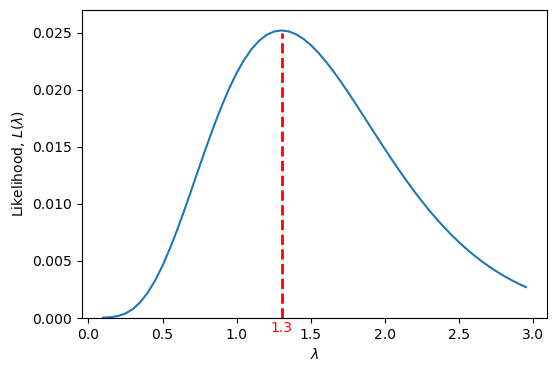

In [2]:
from scipy.stats import expon

x = [0.92, 0.54, 1.20, 0.051, 1.13]

lamgrid = np.arange(0.1,3,0.05)
L_lambda = [np.exp(np.sum(expon.logpdf(x,scale=1/lam))) for lam in lamgrid]

plt.figure(figsize=[6,4])
plt.plot(lamgrid,L_lambda)
plt.xlabel("$\lambda$")
plt.ylabel("Likelihood, $L(\lambda)$")
plt.ylim(0,0.027)
plt.text(1.3,-0.0003,"1.3",ha="center",va="top",color='red')
plt.vlines(x=1/np.mean(x), ymin=0, ymax=0.025, color='red', linestyle='--', linewidth=2, label='Segment')
plt.show()

**Important:** The plot above does **not** depict a "probability distribution" for $\lambda$. This is **not** a density. Instead, it is meant to show, for each possible value of the unknown $\lambda$, what is the likelihood that the observed data would have arisen?

We observe that the likelihood is maximized when $\lambda = 1.3$. Hence, the maximum likelihood estimate of $\lambda$ is $\widehat \lambda = 1.3$.

\newpage

Note that the likelihood function is positive at its maximum. For this reason, the **log-likelihood function** is maximized at the same value as is the likelihood function.

The log-likelihood is denoted $\ell(\theta)$.

The log-likelihood function in our example is shown below.

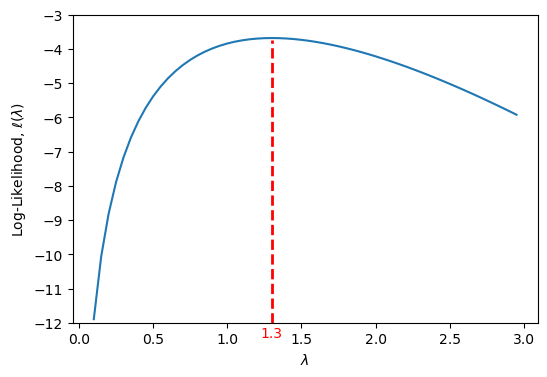

In [3]:
ell_lambda = [np.sum(expon.logpdf(x,scale=1/lam)) for lam in lamgrid]

plt.figure(figsize=[6,4])
plt.plot(lamgrid,ell_lambda)
plt.xlabel("$\lambda$")
plt.ylabel("Log-Likelihood, $\ell(\lambda)$")
plt.ylim(-12,-3)
plt.text(1.3,-12.1,"1.3",ha="center",va="top",color='red')
plt.vlines(x=1/np.mean(x), ymin=-12, ymax=-3.75, color='red', linestyle='--', linewidth=2, label='Segment')
plt.show()

The log-likelihood is computationally easier to maximize. Note that in the iid case the likelihood is calculated as the product of the marginal densities. Even if the sample size is moderately large, this product will be either very large or very close to 0. The log function switches this into a sum over terms, and results in more reasonable values that avoid numerical issues.

The log-likelihood also has desirable theoretical properties which we will discuss soon. 

**Exercise (Important Result):** Suppose that our model assumes that $Y_i = m(\boldsymbol{\theta},{\bf x}_i) + \epsilon_i$, where the $\epsilon_i$ are iid normal$(0,\sigma^2)$ for $i=1,2,\ldots,n$. Show that maximizing the log-likelihood function for $\boldsymbol{\theta}$ is equivalent to minimizing the least squares criterion.

\answerlines{20}

\newpage

## Numerical Likelihood Maximization {-}

For most models of interest, the most direct way to obtain maximum likelihood estimates is to use numerical optimization procedures.

Python includes general-purpose optimization capability; here we will focus on
`minimize()`, a part of `scipy`, which minimizes a function specified by the user.

In [4]:
from scipy.optimize import minimize

\newpage

We'll begin by using our Exponential$(\lambda)$ example from above.

Start by building the function which is to be **minimized**, the negative of the log-likelihood.

In [5]:
def neg_loglike_exp(lamda, x):
    return (-1)*len(x)*np.log(lamda)+lamda*np.sum(x)

Now, we'll actually call `minimize()` to do the optimization. See `help(minimize)` for more information.

In [6]:
res = minimize(neg_loglike_exp,1,method='Nelder-Mead',options={'disp': True},args=(x))

Optimization terminated successfully.
         Current function value: 3.681474
         Iterations: 14
         Function evaluations: 28


\newpage 

Comments:

1. It is crucial that the first input argument to the function to
be minimized (in this example, `neg_loglike_exp()`) be the variable(s)
over which the function is to be optimized. If there is more than one
such variable, then the variables must come in as an array. (We'll do
such an example below.) In this example, we are minimizing over $\lambda$,
so `lamda` goes in as the first argument.

2. There can be any number of additional arguments to the function,
but these must start with the second in the list. Their values
will be passed on to `neg_loglike_exp()` through the optimization function.

3. The first argument to `minimize()` is the function to be minimized. Note
that there are no parentheses; it's simply the name of the function.

4. The second argument to `minimize()` (1 in this example)
is the starting values for the parameter(s) over which the function
will be minimized. This
should be on the interior (not the boundary) of the space of
possible values for the parameter(s). If there is more than one
parameter, then this argument should be an array.

\newpage

5. The `method` argument tells `minimize` which minimization technique
to utilize. Here, I am using `Nelder-Mead`, i.e., the classic optimization
approach of Nelder and Mead. See `help(minimize)` for some guidance on
the available methods.

6. The `options` argument can set various properties, including the
maximum number of iterations, the tolerance, and, as in the example,
the amount of information displayed. The available options will vary
depending on the `method` chosen.

7. Any arguments which are to be passed on to the function 
to be minimized are then listed via the `args` syntax.

8. The input value at which the function is minimized is found via the following:

In [7]:
res.x

array([1.30175781])

\newpage

**Example:** Consider the example below. This function returns the MLE of the parameters $(\alpha, \beta)$
when the observations are assumed to be iid Gamma$(\alpha, \beta)$.

Note how the `gamma.logpdf` function is used to facilitate this, but it is necessary to be careful with the parameterization used by the function.

In [8]:
from scipy.stats import gamma

def gammamle(x):
        
    def neg_loglike(pars,x):
        return (-1)*sum(gamma.logpdf(x,pars[0],scale=1/pars[1]))
    
    mleout = minimize(neg_loglike,[1,1], args=(x), method="Nelder-Mead")
    
    return mleout

**Exercise:** Experiment with the example below to explore the performance.

In [9]:
x = gamma.rvs(5,scale=2,size=100)
gammamle(x).x

array([4.71527751, 0.46440482])

\answerlines{5}

\newpage

**Example: Regression with t-distributed Errors**


In this example, we will consider the following regression model: The
response $Y$ is related to the single predictor by
\begin{equation*}
   Y = \beta_0 + \beta_1 x + \sigma \epsilon
\end{equation*}
where the $\epsilon$ are assumed to have
the $t$-distribution with
$\nu$ degrees of freedom. We will assume that $\nu$ is set by the
user (not estimated).

There are three unknown parameters in this model: $\beta_0$, $\beta_1$,
and $\sigma$. We seek to estimate these via maximum likelihood.

**Exercise:**
We assume that we will observe $n$ pairs of $(x,Y)$ values, and that
the $\epsilon$ values are independent. Derive the density for a
single $Y$ observation.

\answerlines{12}

\newpage

In preparation for using `minimize()`, here is a function that
returns the negative log-likelihood as a function of the three
parameters.

In [10]:
def neg_loglike_treg(pars, x, y, nu):
    
    from scipy.stats import t
    
    resids = y - (x*pars[1] + pars[0])
    return (-1)*sum(t.logpdf(resids/pars[2],nu))+len(x)*np.log(pars[2])

**Exercise:** Explain the structure of the above function.
    
\answerlines{10}

\newpage

This function will fit the model using the assumed $t$-distributed errors. Note that the least squares estimates of the parameters are used as the initial values.

In [11]:
def treg(x,y,nu):
    
    from scipy.stats import t
    
    def neg_loglike_treg(pars, x, y, nu):
        resids = y - (x*pars[1] + pars[0])
        return (-1)*sum(t.logpdf(resids/pars[2],nu))+len(x)*np.log(pars[2])
    
    holdcov = np.cov(x,y)
    
    beta1init = holdcov[0,1]/holdcov[0,0]
    beta0init = np.mean(y) - np.mean(x)*beta1init
    
    resids = y - (beta0init + beta1init*x)
    
    sigmainit = np.sqrt(sum(resids**2)/len(x))
    
    optout = minimize(neg_loglike_treg,[beta0init,beta1init,sigmainit],
                      args=(x,y,nu), method="Nelder-Mead")
      
    return optout

\newpage

**Exercise:** Consider the code below to assess the behavior of the function. 

\answerlines{10}

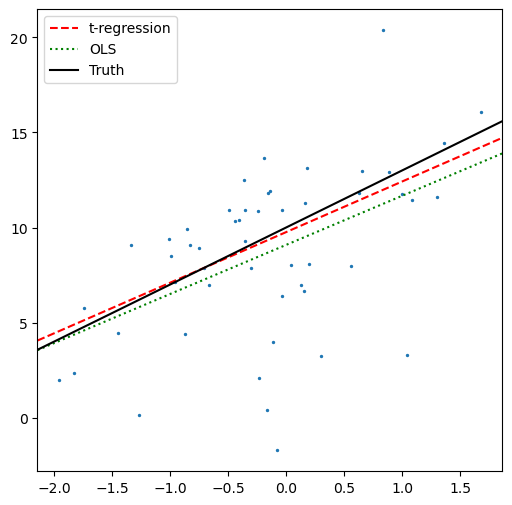

In [12]:
from scipy.stats import t,norm
import statsmodels.api as sm

x = norm.rvs(size=50)
y = 10 + 3*x + 3*t.rvs(df=3,size=len(x))
df_t = pd.DataFrame({"x":x,"y":y})

tregfit = treg(x,y,3).x

lsfit = sm.OLS.from_formula("y~x",data=df_t).fit()

plt.figure(figsize=[6,6])
plt.scatter(x,y,s=2)
plt.axline([0,tregfit[0]],slope=tregfit[1],label="t-regression",
           color="red",linestyle="--")
plt.axline([0,lsfit.params['Intercept']],slope=lsfit.params['x'],
           label="OLS",color="green",linestyle=":")
plt.axline([0,10],slope=3,label="Truth",color="black")
plt.legend()

plt.show()

\newpage

**Example: The GARCH(1,1) Model**

GARCH stands for **generalized autoregressive conditionally heteroskedasticity**,
which is a class of models capable of capturing **volatility clustering** often present in financial time series, especially in log returns.

The GARCH(1,1) model can be described as follows: The observation at time $t$, denoted $X_t$ is normal with mean zero and variance
\begin{equation*}
   \sigma_t^2 = \omega + \alpha X_{t-1}^2 + \beta \sigma_{t-1}^2.
\end{equation*}

In other words, the variance at time $t$ depends on the amount of variability in the previous observation. 

Additional terms can be added to model dependence on a greater number of lags, and distribution assumptions other than the normal can be used, but here we will focus on this basic form.

The three parameters of the model $\boldsymbol{\theta} = (\omega, \alpha, \beta)$ can be estimated using maximum likelihood.

\newpage

**Exercise:** Derive the likelihood function $L(\boldsymbol{\theta})$ for the GARCH(1,1) model.

\answerlines{20}

\newpage

The following function calculates the negative of the log-likelihood in this case. Note that in order to do the iterations, a value for $\sigma^2_0$ has to be fixed. Here, we use the $\omega/(1-\alpha-\beta)$, which is equal to the unconditional variance for $X_t$ as a  function of the parameters.

In [13]:
def neg_loglike_garch11(params, x):
    
    omega, alpha, beta = params
    
    sigma2 = np.zeros(len(x))
    
    sigma2[0] = omega/(1-alpha-beta)
    
    for t in range(1, len(x)):
        sigma2[t] = omega + alpha * x[t-1]**2 + beta * sigma2[t-1]
    
    neg_loglike = -np.sum(norm.logpdf(x,loc=0,scale=np.sqrt(sigma2)))
    
    return neg_loglike

\newpage

Let's try this with some observed log returns.

In [14]:
symb = "VOYA"
EQohlc = yf.Ticker(symb).history(start="2023-01-01", end="2025-12-31")
EQldr = np.log(EQohlc['Close']).diff().dropna()

When fitting a GARCH model, it is a good idea to scale the series prior to fitting, since the original values can be close to zero, especially after being squared.

In [15]:
scl_data = np.array(EQldr)/np.std(EQldr)

Now call the `minimize` function. Here, we use the `bounds` functionality to force the iterative algorithm to observe the constraints on the parameters. This does not work with all optimization methods, but it does with `L-BFGS-B`.

Sometimes the procedure will not work with lower bounds exactly equal to zero, and in such cases you may have to replace `0` with something such as `1e-6`.

In [16]:
initial_guess = [np.var(scl_data), 0.1, 0.1]

bounds = (
    (0, None),   # omega
    (0, 0.999),  # alpha
    (0, 0.999)   # beta
)

res = minimize(
    neg_loglike_garch11,
    initial_guess, 
    args=(scl_data,), 
    method='L-BFGS-B',
    bounds=bounds
)

In [17]:
print(res)

  message: CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
  success: True
   status: 0
      fun: 1011.9244931436206
        x: [ 2.742e-01  2.643e-01  4.830e-01]
      nit: 10
      jac: [-4.434e-04 -9.209e-04 -2.547e-03]
     nfev: 56
     njev: 14
 hess_inv: <3x3 LbfgsInvHessProduct with dtype=float64>


\newpage

Not surprisingly, there are existing functions for fitting such models. The example below uses the package `arch`.

In [18]:
from arch import arch_model

model = arch_model(scl_data, vol='GARCH', p=1, q=1,
        mean="Zero").fit(update_freq=0,cov_type="classic")

model.summary()

Optimization terminated successfully    (Exit mode 0)
            Current function value: 1011.6555062789815
            Iterations: 7
            Function evaluations: 33
            Gradient evaluations: 7


<class 'statsmodels.iolib.summary.Summary'>
"""
                       Zero Mean - GARCH Model Results                        
==============================================================================
Dep. Variable:                      y   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.001
Vol Model:                      GARCH   Log-Likelihood:               -1011.66
Distribution:                  Normal   AIC:                           2029.31
Method:            Maximum Likelihood   BIC:                           2043.17
                                        No. Observations:                  750
Date:                Tue, Sep 22 2026   Df Residuals:                      750
Time:                        16:36:16   Df Model:                            0
                            Volatility Model                            
========================================================================
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
omega          0.2732  5.136e-02      5.319  1.041e-07 [  0.173,  0.374]
alpha[1]       0.2568  6.015e-02      4.269  1.965e-05 [  0.139,  0.375]
beta[1]        0.4861  6.715e-02      7.239  4.534e-13 [  0.354,  0.618]
========================================================================

Covariance estimator: classic
"""